In [21]:
print("Week 1 task")

import pandas as pd
import random

random.seed(42)

names = [
    "Thando Mthembu", "Zanele Dlamini", "Sipho Nkosi",
    "Ayanda Zulu", "Lerato Mokoena", "John Smith",
    "Mary Jones", "Sibusiso Khumalo", "Nomsa Naidoo",
    "Peter Brown", "Nandi Ndlovu", "David Adams"
]

domains = [
    "Data Science", "Web Development", "Cybersecurity",
    "Software Engineering", "Data Analytics"
]

universities = [
    "UKZN", "UCT", "Wits", "University of Pretoria",
    "University of Johannesburg"
]

statuses = ["Under Review", "Selected", "Rejected"]

data = []

for i in range(80):
    name = random.choice(names)
    data.append({
        "Applicant Name": name,
        "Email": f"{name.lower().replace(' ','')}@gmail.com",
        "Phone": f"0{random.choice([6, 7, 8])}{random.randint(10000000, 99999999)}",
        "Domain Applied": random.choice(domains),
        "University": random.choice(universities),
        "Application Date": (
            pd.Timestamp("2026-01-01")
            + pd.Timedelta(days=random.randint(0, 250))
        ).strftime("%Y-%m-%d"),
        "Status": random.choice(statuses)
    })

df = pd.DataFrame(data)

# Introduce intentional data-quality issues
df.loc[2, "Email"] = None
df.loc[7, "Phone"] = None
df.loc[12, "University"] = None
df.loc[17, "Status"] = None
df.loc[5, "Applicant Name"] = "  Thando Mthembu  "
df.loc[10, "Domain Applied"] = "data science"
df.loc[15, "Status"] = "selected"
df.loc[20, "Email"] = "not-an-email"
df.loc[25, "Phone"] = "abc123"
df.loc[30, "Application Date"] = "15/05/2026"
df.loc[35, "Domain Applied"] = "Graphic Design"
df.loc[40, "University"] = " ukzn "
df.loc[45, "Applicant Name"] = None
df.loc[50] = df.loc[3]
df.loc[51] = df.loc[3]

# Save the dataset
df.to_csv("applicants.csv", index=False)

#print("Dataset created!")
#print(df)  #For print your dataset


"""
This is the info we first explore before we start cleaning the data
"""
print("Shape: ",df.shape) # how many rows and columns?
print("Head: ",df.head()) # preview the first 5 rows
print("Info: ",df.info()) # data types + non-null counts per column
print("Missing values per column: ",df.isnull().sum()) # exact count of missing values per column
print("Duplicated data: ",df.duplicated().sum()) # how many exact duplicate rows exist

#Creating the clean dataset var
clean_data= df.copy()
# Summary of missing values in every column
print("MISSING VALUES PER COLUMN:")
print(clean_data.isnull().sum())

# Show the actual rows containing missing values
print("\nROWS WITH MISSING VALUES:")
display(clean_data[clean_data.isnull().any(axis=1)])

# Summary of duplicate rows
print("\nNUMBER OF DUPLICATE ROWS:")
print(clean_data.duplicated().sum())

# Display all duplicate occurrences
print("\nDUPLICATE ROWS:")
display(clean_data[clean_data.duplicated(keep=False)])

#Now we have the data with errors printed and let solve their problem

'''
This part helps with removing the application if it had no name
'''
missing_name = clean_data['Applicant Name'].isna()
# Remove applications with missing names
clean_data = clean_data.loc[~missing_name].copy() #Deleting those application



#Treat empty strings and spaces as missing values
for col in ['Email', 'Phone']:
    clean_data[col] = clean_data[col].replace(r'^\s*$', pd.NA, regex=True)
#Identify applications based on contact information
missing_both =(
          clean_data['Email'].isna()&
          clean_data['Phone'].isna()
          )
needs_sms = (
          clean_data['Email'].isna()& clean_data['Phone'].notna()
          )
needs_email = (
    clean_data['Email'].notna()& clean_data['Phone'].isna()
    )

#Display applications missing BOTH contact methods
print("APPLICATIONS MISSING BOTH EMAIL AND PHONE")
display(clean_data.loc[missing_both])

#Prepare SMS follow-up list
sms_list = clean_data.loc[needs_sms].copy()
sms_list['Message'] = (
    "Hello, your application is missing an email address. "
    "Please provide your email address to complete your records.")
print("APPLICANTS TO CONTACT BY SMS")
display(sms_list[['Phone', 'Message']])
#Prepare email follow-up list
email_list = clean_data.loc[needs_email].copy()
email_list['Subject'] = "Missing phone number"
email_list['Message'] = (
    "Hello, your application is missing a phone number. "
    "Please provide your phone number to complete your records."
    )

print("APPLICANTS TO CONTACT BY EMAIL")
display(email_list[['Email', 'Subject', 'Message']])
#Remove applications missing BOTH contact methods
#This changes clean_data only; df remains unchanged.
clean_data = clean_data.loc[~missing_both].copy()

# Replacing missing values on email and phone number to indicate
# follow_up_required
clean_data['Email'] = clean_data['Email'].fillna('Follow-up Required')
clean_data['Phone'] = clean_data['Phone'].fillna('Follow-up Required')

#Handling missing values on the university col
clean_data['University'] = clean_data['University'].fillna('Not Specified')
#Handling missing values on the university col
clean_data['Status'] = clean_data['Status'].fillna('Under Review')

# Remove duplicate rows, keeping only the first occurrence
clean_data = clean_data.drop_duplicates() # Remove exact duplicate rows
print("Duplication is deleted .")
#Standardize casing, due to the nature of our data we eliminated that possible errors
# by for a box like scenairo where you choose instead of writing , thus there will
# no need to standardize since user won't be writing their own thing.

#Convert Application Date to a real date type, although this part was done above
# but for more clarification we do this
clean_data['Application Date'] = pd.to_datetime(
    clean_data['Application Date'], format='mixed', dayfirst=True, errors='coerce'
)
#Clean up Phone number by removing dashes/spaces
clean_data['Phone'] = clean_data['Phone'].str.replace('-', '', regex=False).str.replace(' ','', regex=False)
clean_data.info()


#Display the cleaned dataset
print("\nCLEANED DATASET")
display(clean_data)
print(clean_data.isnull().sum()) # Check any missing value when done cleaning
clean_data.to_csv('applicants_cleaned.csv', index=False)
from google.colab import files
files.download("applicants_cleaned.csv")

Week 1 task
Shape:  (80, 7)
Head:     Applicant Name                  Email       Phone   Domain Applied  \
0    Nandi Ndlovu  nandindlovu@gmail.com  0613356886    Cybersecurity   
1     David Adams   davidadams@gmail.com  0683197857     Data Science   
2  Thando Mthembu                   None  0639345092  Web Development   
3    Nomsa Naidoo  nomsanaidoo@gmail.com  0697226012   Data Analytics   
4     Peter Brown   peterbrown@gmail.com  0710872248  Web Development   

                   University Application Date        Status  
0                         UCT       2026-02-27  Under Review  
1  University of Johannesburg       2026-04-19  Under Review  
2  University of Johannesburg       2026-06-04  Under Review  
3      University of Pretoria       2026-02-26      Selected  
4      University of Pretoria       2026-03-29      Selected  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype 


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
2,Thando Mthembu,None,0639345092,Web Development,University of Johannesburg,2026-06-04,Under Review
7,Nomsa Naidoo,nomsanaidoo@gmail.com,None,Data Science,University of Johannesburg,2026-03-17,Rejected
12,Nomsa Naidoo,nomsanaidoo@gmail.com,0842857966,Web Development,None,2026-04-08,Selected
17,Nomsa Naidoo,nomsanaidoo@gmail.com,0788461803,Software Engineering,University of Johannesburg,2026-04-13,None
45,None,ayandazulu@gmail.com,0687736262,Data Analytics,UKZN,2026-07-11,Selected



NUMBER OF DUPLICATE ROWS:
2

DUPLICATE ROWS:


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
3,Nomsa Naidoo,nomsanaidoo@gmail.com,0697226012,Data Analytics,University of Pretoria,2026-02-26,Selected
50,Nomsa Naidoo,nomsanaidoo@gmail.com,0697226012,Data Analytics,University of Pretoria,2026-02-26,Selected
51,Nomsa Naidoo,nomsanaidoo@gmail.com,0697226012,Data Analytics,University of Pretoria,2026-02-26,Selected


APPLICATIONS MISSING BOTH EMAIL AND PHONE


...

Duplication is deleted .
<class 'pandas.core.frame.DataFrame'>
Index: 77 entries, 0 to 79
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    77 non-null     object        
 1   Email             77 non-null     object        
 2   Phone             77 non-null     object        
 3   Domain Applied    77 non-null     object        
 4   University        77 non-null     object        
 5   Application Date  77 non-null     datetime64[ns]
 6   Status            77 non-null     object        
dtypes: datetime64[ns](1), object(6)
memory usage: 4.8+ KB

CLEANED DATASET


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Nandi Ndlovu,nandindlovu@gmail.com,0613356886,Cybersecurity,UCT,2026-02-27,Under Review
1,David Adams,davidadams@gmail.com,0683197857,Data Science,University of Johannesburg,2026-04-19,Under Review
2,Thando Mthembu,Follow-up Required,0639345092,Web Development,University of Johannesburg,2026-06-04,Under Review
3,Nomsa Naidoo,nomsanaidoo@gmail.com,0697226012,Data Analytics,University of Pretoria,2026-02-26,Selected
4,Peter Brown,peterbrown@gmail.com,0710872248,Web Development,University of Pretoria,2026-03-29,Selected
...,...,...,...,...,...,...,...
75,Ayanda Zulu,ayandazulu@gmail.com,0715957459,Software Engineering,UKZN,2026-05-14,Rejected
76,Nandi Ndlovu,nandindlovu@gmail.com,0836445607,Cybersecurity,University of Pretoria,2026-01-18,Rejected
77,John Smith,johnsmith@gmail.com,0852133044,Data Science,Wits,2026-05-10,Selected
78,Nandi Ndlovu,nandindlovu@gmail.com,0753779528,Software Engineering,Wits,2026-05-22,Under Review


Applicant Name      0
Email               0
Phone               0
Domain Applied      0
University          0
Application Date    0
Status              0
dtype: int64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Week 1: Data Cleaning

**Name:** Snethemba Asande Mthembu

**Programme:** Data Science Internship – NextGen Learners

**Task:** Week 1 – Data Cleaning

This notebook documents my data cleaning journey, including loading, inspecting, and preparing data for analysis using Python and Pandas.

**Exploring dataset before cleaning it**

The dataset has 80 rows and 7 columns.The following columns have the missing values, respective to their count.*Application name* 1,*Email* 1,*Phone number* 1, *Domain applied* 0,*University* 1, *Application date* 0, *Status* 1. We also have 2 duplicate rows on our data.After exploring our dataset I printed those line with the errors so cleaning will be easy.The way we're going to clean data , we're pin pointing the row and fixing that problem.

On rows with the missing either the phone number or an email , the one with the missing email we send an sms to ask for more info and on our dataset we write *follow_up+required* on email space.For the one with the missing phone number we can write an email to request for the phone number and on our dataset we write *follow_up_required* on phone space. This is done because mistakes can happen while doing the application and sometimes people can be confused what is needed on that space. But for those who did not provide us with both their application is deleted.

On row 12 we have the missing value on the University column , thus we write *Not Specified* as suggested on the handbook.

On row 17 we also have a missin value on Status column and we also write *Not Specified*.

On row 45 we have the missing name value thus delete this application since name is considered as the critical info on our dataset.But for this we wrote a command that delete application with the missing name value for the future application to be handle proper not to direct to everything one-by-one.

When removing the duplicate we take email into consideration to see search for duplicate. The application that have the same email and the same Applied Domain is considered as the same but we must also consider the name as well as the phone number just to prevent posible error. There after we can conclude that we have duplicate and remove them and keep the first one.


On my dataset the standardize Text fields the domain mappign was clearly specified , if we were to put it on the real-world application it would have been in the form of you chose from the collectio and pick one at a time in order avoid any errors same applies on the status.


For more accuracy of our datasest we do the following, convert application data to a real date type ,clean up phone numbers.Although on our dataset that we randomly created ,we don't have this errors but in real life peopledo it.So we wrote a code to handle this part


**Summary**

*Issues found: *
       
       row 2 :missing Email
       row 7 :missing Phone number
       row 12: missing University
       row 17: missing Status
       row 45 :Missing Applicant Name
       row 3 and 51 : duplicates

*Action taken:*

-row 2 , replaced with *follow_up_required* to indicate for request of email.

-row 7 ,replaced with *follow_up_required* to indicate for request of phone number.

-row 12 , replaced with *Not Specified*.

-row 117 , replaced with *Not Specified*.

-Remove missing Applicant Name application because that one is critical.

-Duplicates were removed and the first one was kept.

**Final dataset**: 77 rows, 7 columns, no missing values in critical fields , no duplicates, consistent formatting throughout.



**Week 2- Exploratory Data Analysis:NextGenLeaners Applicant Insights**

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    77 non-null     object        
 1   Email             77 non-null     object        
 2   Phone             77 non-null     object        
 3   Domain Applied    77 non-null     object        
 4   University        77 non-null     object        
 5   Application Date  77 non-null     datetime64[ns]
 6   Status            77 non-null     object        
dtypes: datetime64[ns](1), object(6)
memory usage: 4.3+ KB
Domain Applied
Web Development         20
Software Engineering    20
Data Science            14
Data Analytics          12
Cybersecurity            9
data science             1
Graphic Design           1
Name: count, dtype: int64


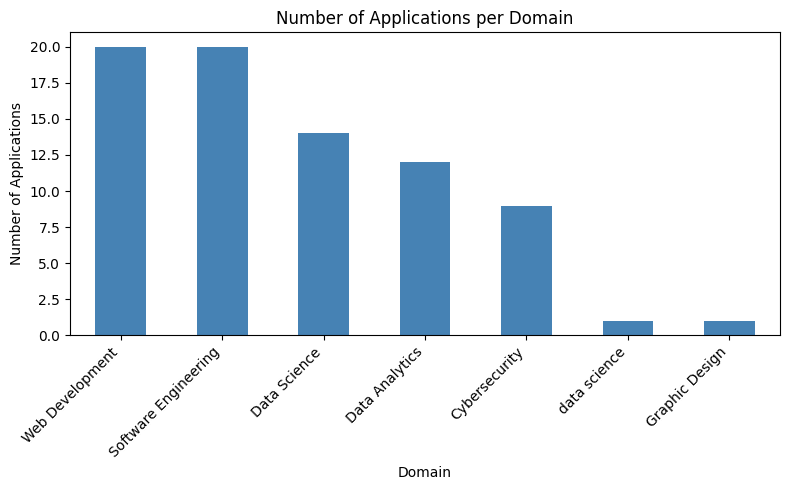

Application Month
2026-01    10
2026-02     7
2026-03     8
2026-04    11
2026-05     9
2026-06    11
2026-07    11
2026-08     8
2026-09     2
Freq: M, dtype: int64


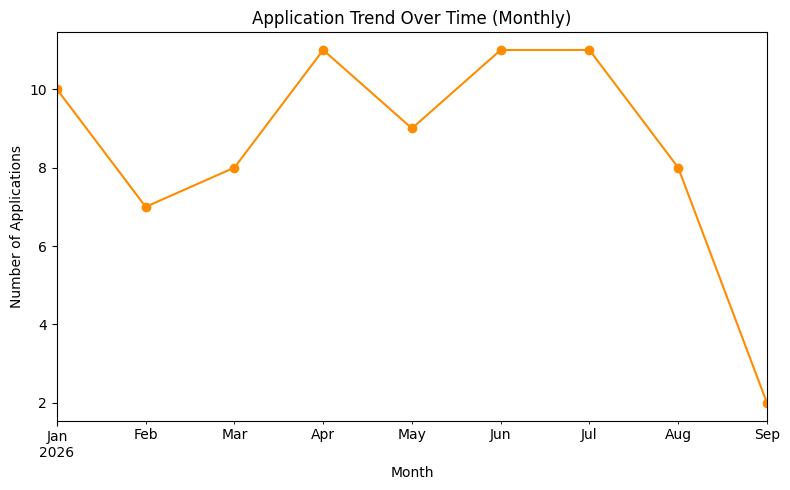

Status
Under Review    33
Rejected        23
Selected        21
Name: count, dtype: int64
Status                Rejected  Selected  Under Review
Domain Applied                                        
Cybersecurity                2         4             3
Data Analytics               4         3             5
Data Science                 5         4             5
Graphic Design               0         0             1
Software Engineering         7         4             9
Web Development              5         6             9
data science                 0         0             1
Status                Rejected  Selected  Under Review
Domain Applied                                        
Cybersecurity             22.2      44.4          33.3
Data Analytics            33.3      25.0          41.7
Data Science              35.7      28.6          35.7
Graphic Design             0.0       0.0         100.0
Software Engineering      35.0      20.0          45.0
Web Development           25.0

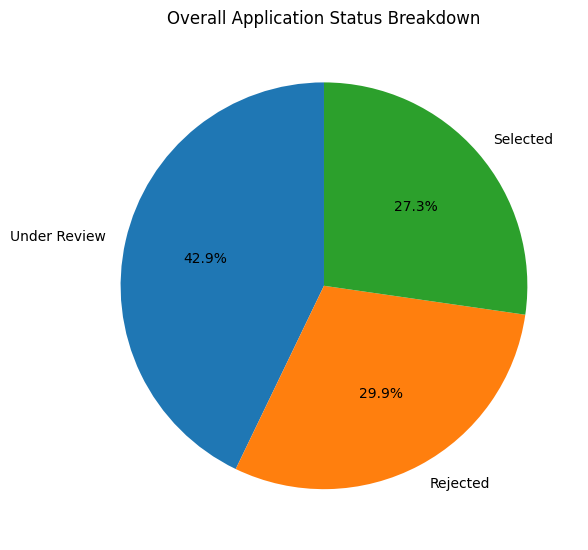

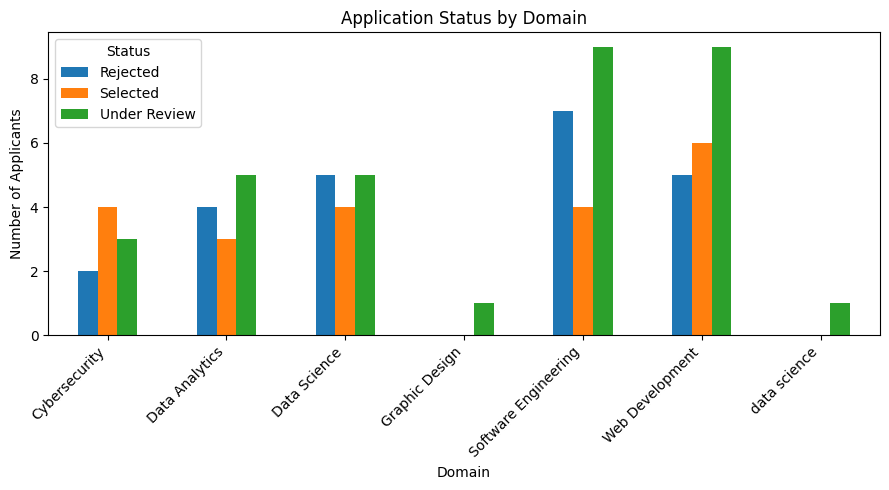

University
Wits                          20
UKZN                          17
University of Pretoria        14
University of Johannesburg    13
UCT                           11
Not Specified                  1
 ukzn                          1
Name: count, dtype: int64


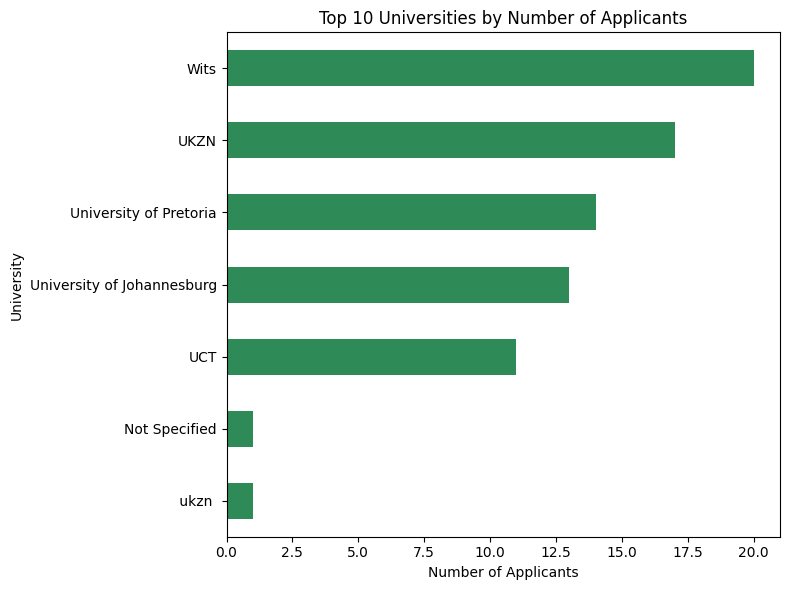

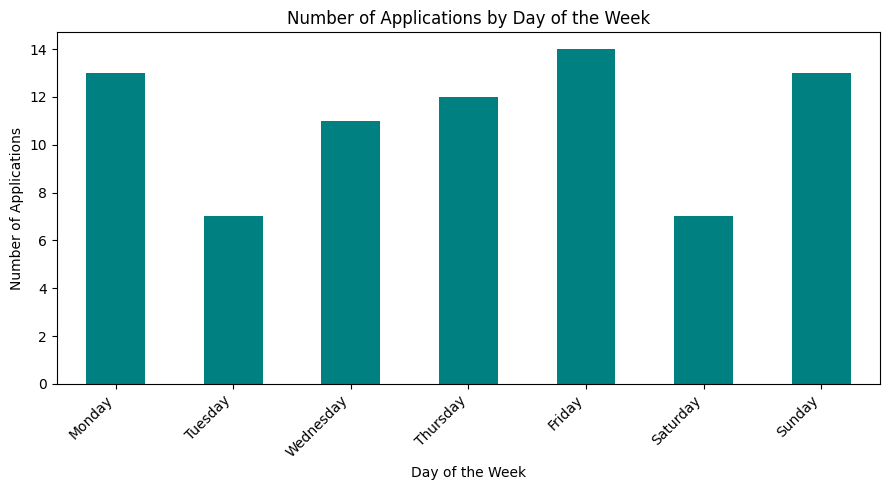

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('applicants_cleaned.csv', parse_dates=['Application Date'])
df.info()  #Just to check whether our data is clean?
df.head()
df['Status'] = df['Status'].str.strip().str.title() # To prevent any errors related to treating status written in uppercase and lowercase different
domain_counts = df['Domain Applied'].value_counts()
print(domain_counts)
plt.figure(figsize=(8,5))
domain_counts.plot(kind='bar', color='steelblue')
plt.title('Number of Applications per Domain') # Our chart title
plt.xlabel('Domain')                           #x-axis for the domainapplied
plt.ylabel('Number of Applications')           #y-axis for the number of application
plt.xticks(rotation=45, ha='right')#Rotates the domain names on the x-axis so long labels don't overlap and become unreadable
plt.tight_layout()
plt.show()

# Group by month
df['Application Month'] = df['Application Date'].dt.to_period('M')
monthly_trend = df.groupby('Application Month').size()
print(monthly_trend)

plt.figure(figsize=(8,5))
monthly_trend.plot(kind='line', marker='o', color='darkorange')
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.tight_layout()
plt.show()

#Overall status breakdown
status_counts = df['Status'].value_counts()
print(status_counts)
status_by_domain = pd.pivot_table(
 df,index='Domain Applied',
 columns='Status',
 values='Applicant Name',
 aggfunc='count',
 fill_value=0
)
print(status_by_domain)

status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1),axis=0) * 100
print(status_by_domain_pct.round(1))
# Overall status - pie chart
plt.figure(figsize=(6,6))
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Overall Application Status Breakdown')
plt.ylabel('') # removes the default awkward y-label pie charts add
plt.tight_layout()
plt.show()
# Per-domain - grouped bar chart
status_by_domain.plot(kind='bar', figsize=(9,5))
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

#Which Universities sent the most applicants?
top_universities = df['University'].value_counts().head(10)
print(top_universities)

plt.figure(figsize=(8,6))
top_universities.sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

# Applications by day of the week

df['Day of Week'] = df['Application Date'].dt.day_name()

# Arrange days in calendar order
day_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

day_counts = (
    df['Day of Week']
    .value_counts()
    .reindex(day_order, fill_value=0)
)

# Create the chart
plt.figure(figsize=(9, 5))
day_counts.plot(kind='bar', color='teal')

plt.title('Number of Applications by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


**TASK 2-EXPLORATORY DATA ANALYSIS**

First we count the number of doamins we have and then draw the chart to represent the number of applicants on each domain.eg On Cybersecurity domain we have 9 applicants.
When drawing the chart we use the matplotlib.pyplo libraries.

Now we group the applications by months and draw a line chart to show fluctuation of application. Applications fluctuated throughout 2026, peaking in April, June and July at around 11 applications per month. After July, applications declined, reaching their lowest point in September, with only 2 applications. This suggests that application activity decreased towards the end of the observed period.

Afterwards we create a pivot table to show us clearly for each domain how many were rejected, selected and underview.This helps use to draw our pie chart and the grouped bar chart.

Chart of the universities with the most applicants is drawn and on our case it's Wits and with the lowest is UKZN.

*Applications by Day of the Week*,
This chart shows the number of applications submitted on each day of the week. I chose this question to explore whether application activity is higher on weekdays or weekends and to identify which days receive the most and fewest applications. This may help reveal patterns in applicant submission behaviour.


**SUMMARY**

-Web development is the most popular domain by far , receiving 10x more applications than the least popular domain(Graphc Design).

-Applications peaked at April and then decreased and also peaked at June and July, and decreased afterwards.

-While Web Development has the higher application vloume , Cybersecurity has a notibly higher acceptance rate(30.0 vs 44.4).

-Applicants are concentrated on the first two unirvesities and then it gradually decreases for the next 4 universities.

-Most applications are still awaiting a decision: Under Review accounts for 33 applications, more than Rejected (23) or Selected (21), meaning the largest group has not yet received a final outcome.

-Application submissions vary across the days of the week: Friday recorded the highest number of applications (14), while Tuesday and Saturday had the fewest (7 each).
